# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

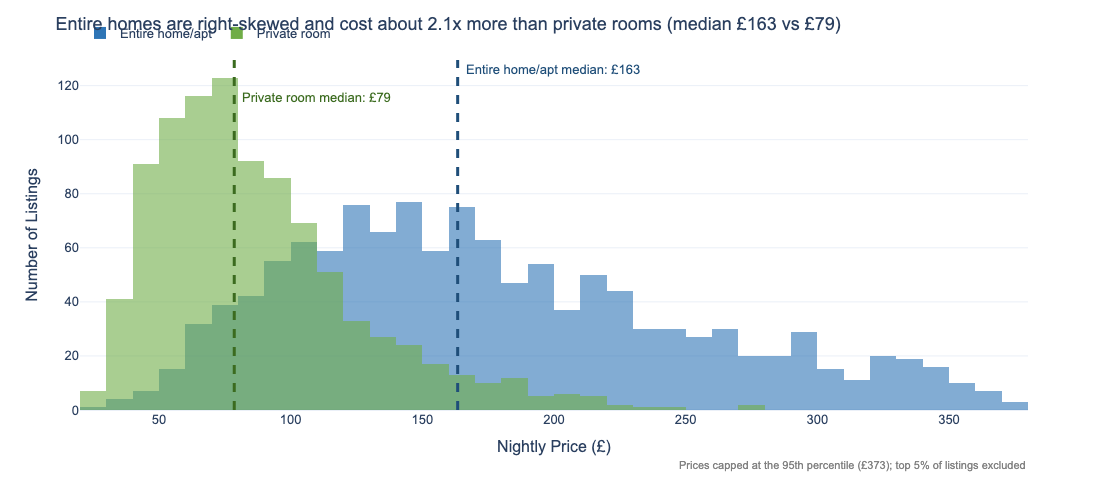

In [3]:
# Task 1
# YOUR CODE HERE
# Task 1 - overlapping histogram of price: Entire home/apt vs Private room

# Keep only the two room types we compare (Shared room has too few listings)
two = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])]

# Median price of each room type: a small table with one number per room type
medians = two.groupby('room_type')['price'].median()

# Build the histogram
fig = px.histogram(
    data_frame=two,                      
    x='price',                           
    color='room_type',                   
    barmode='overlay',                   
    opacity=0.6,                         
    nbins=50,                            
    color_discrete_map={'Entire home/apt': '#2E75B6',   
                        'Private room': '#70AD47'},     
    labels={'price': 'Nightly Price (£)', 'room_type': ''},
    template='plotly_white',             
    height=500,
)

# One dashed vertical median line per room type, in a darker version of its colour
line_colours = {'Entire home/apt': '#1F4E79', 'Private room': '#3B6B1F'}
for i, (room, med) in enumerate(medians.items()):   
    fig.add_vline(
        x=med, line_dash='dash', line_width=3, line_color=line_colours[room],
        annotation=dict(
            text=f'{room} median: £{med:.0f}',          
            font=dict(color=line_colours[room], size=13),
            xanchor='left', xshift=6,                   
            y=1 - 0.08 * i, yref='paper',               
        ),
    )

# Disclose the cap (Rule 1): tell the viewer the top 5% was removed
fig.add_annotation(
    text=f'Prices capped at the 95th percentile (£{p95:.0f}); top 5% of listings excluded',
    xref='paper', yref='paper', x=1, y=-0.18,           
    showarrow=False, xanchor='right', font=dict(size=11, color='grey'),
)

# Insight title naming the shape and the gap between the two distributions
gap = medians['Entire home/apt'] / medians['Private room']
fig.update_layout(
    title=(f'Entire homes are right-skewed and cost about {gap:.1f}x more than private rooms '
           f'(median £{medians["Entire home/apt"]:.0f} vs £{medians["Private room"]:.0f})'),
    font=dict(family='Arial', size=13),
    yaxis=dict(title='Number of Listings'),
    legend=dict(orientation='h', x=0, y=1.12, title=''),  
    margin=dict(b=90),                                    
)
fig.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

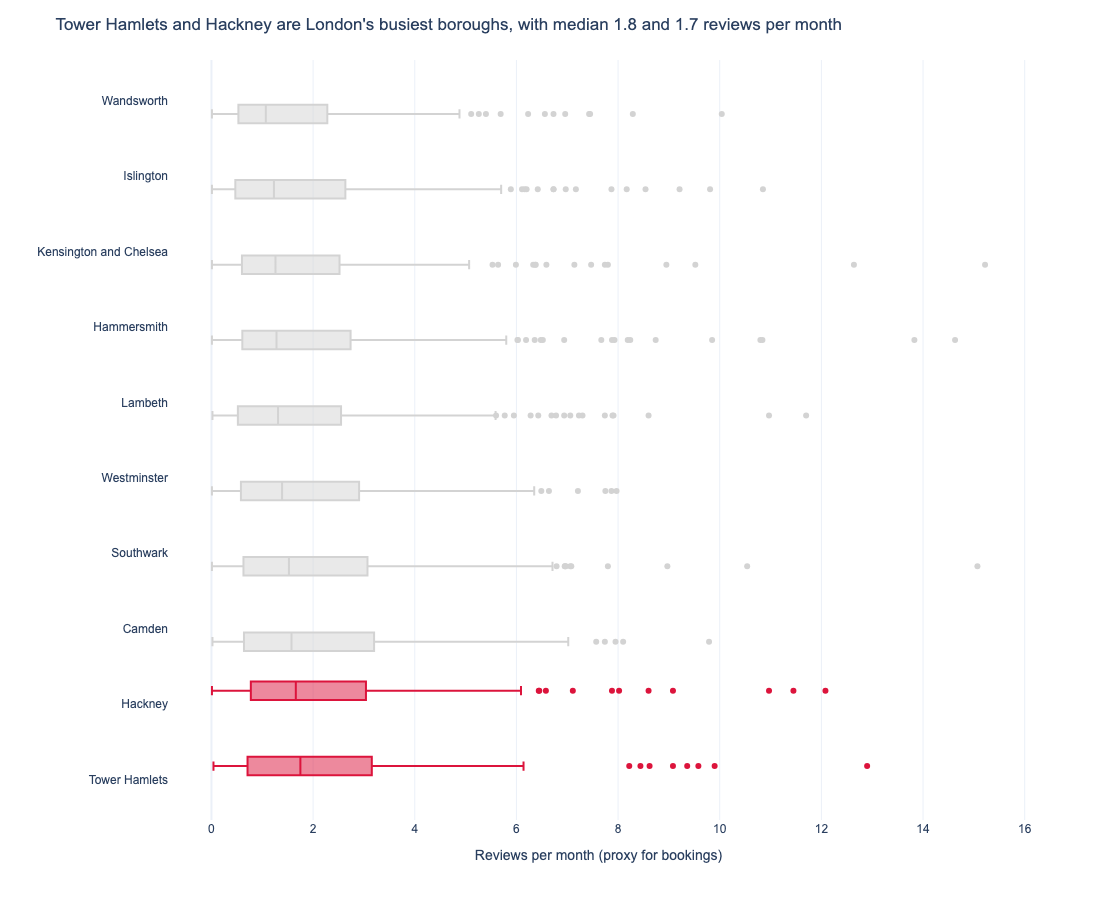

In [4]:
# Task 2
# YOUR CODE HERE
# Task 2 - horizontal box plot: reviews per month by borough

# Remove listings with zero or missing reviews (new/inactive listings)
active = df[df['reviews_per_month'] > 0].copy()  
borough_med = (active.groupby('neighbourhood')['reviews_per_month']
                     .median()
                     .sort_values())
order = borough_med.index.tolist()
top2 = borough_med.index[-2:].tolist()            

# Label each row: 'Top 2' (to highlight) or 'Other' (to grey out)
active['group'] = np.where(active['neighbourhood'].isin(top2), 'Top 2', 'Other')

fig = px.box(
    data_frame=active,
    x='reviews_per_month', y='neighbourhood',     
    color='group',
    color_discrete_map={'Top 2': 'crimson', 'Other': 'lightgrey'},  
    category_orders={'neighbourhood': order},    
    points='outliers',                            
    labels={'reviews_per_month': 'Reviews per month (proxy for bookings)', 'neighbourhood': ''},
    template='plotly_white',
    height=900,
)
fig.update_layout(
    title=(f"{top2[1]} and {top2[0]} are London's busiest boroughs, "
           f"with median {borough_med[top2[1]]:.1f} and {borough_med[top2[0]]:.1f} reviews per month"),
    font=dict(family='Arial', size=12),
    showlegend=False,                         
    yaxis=dict(showgrid=False),
)
fig.show()